In [1]:
import pandas as pd

# Load the Oregon Workers' Compensation dataset
file_path = "/Users/sushmakafle/Documents/Master/ADS-599/export.csv"
df = pd.read_csv(file_path, low_memory=False)

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Display first five records
display(df.head())

# Examine column names and data types
df.info()

Dataset shape: (220302, 31)


,Claim Number,Claim Reference Year,Date of Injury,County of Injury,Age Range,Gender,Occupation Code,Occupation Description,Tenure,Nature of Injury Code,...,NAICS Code (Description),Employer Number,Employer Location Number,Number of employees,Employer Name,Employer Address 1,Employer Address 2,Employer City,Employer State,Employer Zip Code
0,Claim182709,2023,2022Q4,Malheur,45-54,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",2nd-3rd years,1232,...,OILSEED AND GRAIN FARMING,EmpX4442695,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted
1,Claim152988,2021,2021Q4,Sherman,35-44,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",26th and more,111,...,OILSEED AND GRAIN FARMING,EmpX5675530,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted
2,Claim210095,2024,2024Q1,Morrow,25-34,M,452093,"Farmworkers, Farm and Ranch Animals",4th-5th years,132,...,CORN FARMING,8871014,3,50-99,FREDERICKSON FARMING LLC,NaN,80702 PATERSON FERRY RD,IRRIGON,OR,97844
3,Claim165730,2022,2021Q4,Morrow,Over 65,M,493031,Bus and Truck Mechanics and Diesel Engine Spec...,6th-10th years,1839,...,CORN FARMING,8871014,3,50-99,FREDERICKSON FARMING LLC,NaN,80702 PATERSON FERRY RD,IRRIGON,OR,97844
4,Claim36268,2016,2016Q3,Umatilla,25-34,M,452092,"Farmworkers and Laborers, Crop, Nursery, and G...",First month,185,...,OILSEED AND GRAIN FARMING,EmpX840139,Redacted,1-10,Redacted,Redacted,Redacted,Redacted,OR,Redacted


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220302 entries, 0 to 220301
Data columns (total 31 columns):
 #   Column                                    Non-Null Count   Dtype 
---  ------                                    --------------   ----- 
 0   Claim Number                              220302 non-null  object
 1   Claim Reference Year                      220302 non-null  int64 
 2   Date of Injury                            220302 non-null  object
 3   County of Injury                          220302 non-null  object
 4   Age Range                                 220302 non-null  object
 5   Gender                                    220272 non-null  object
 6   Occupation Code                           220302 non-null  int64 
 7   Occupation Description                    220196 non-null  object
 8   Tenure                                    220302 non-null  object
 9   Nature of Injury Code                     220302 non-null  int64 
 10  Nature of Injury (Description)  

### Check Missing Values and Duplicate Records

Identifying missing values and duplicate records to assess the dataset's quality before cleaning. We'll calculate missing percentages.

In [3]:
# Check missing values for each column
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

# Display columns with missing values, highest first
display(
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values(by='Missing_Percentage', ascending=False)
)

# Check for completely duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

,Missing_Count,Missing_Percentage
Employer Address 1,154046,69.92
Employer State,3690,1.67
NAICS Code (Description),1036,0.47
Employer City,1010,0.46
Occupation Description,106,0.05
Gender,30,0.01
Nature of Injury (Description),32,0.01
Employer Address 2,12,0.01
Employer Zip Code,9,0.00


Duplicate records: 0
Duplicate percentage: 0.0 %


The dataset contains 0 duplicate records (0.0%). No duplicate removal is required.

### Examine Numerical and Categorical Variables

Identifying numerical and categorical columns and reviewing their summary statistics. This helps us understand the distribution of values and identify potential data-quality issues.

In [6]:
# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

# Display the number of columns in each group
print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

# Review numerical statistics, including min, max, and quartiles
display(df[numerical_cols].describe().T)

# Review categorical statistics, including unique values and frequency
display(df[categorical_cols].describe().T)

Numerical columns: 8
Categorical columns: 23


,count,mean,std,min,25%,50%,75%,max
Claim Reference Year,220302.0,2019.652250,2.829334,2015.0,2017.0,2020.0,2022.0,2024.0
Occupation Code,220302.0,445687.379034,167577.135913,870.0,352014.0,452093.0,519199.0,999999.0
Nature of Injury Code,220302.0,1034.065782,848.882817,0.0,143.0,1232.0,1232.0,9999.0
Body Part Injured Code,220302.0,774.819716,1369.942297,6.0,52.0,322.0,512.0,9999.0
Event of Injury Code,220302.0,4327.174324,2863.595603,20.0,722.0,4333.0,7111.0,9999.0
Source of Injury Code,220302.0,3532.707384,3141.764258,10.0,562.0,2131.0,6620.0,9999.0
Secondary Source of Injury Code,220302.0,8777.931635,2807.870291,10.0,9999.0,9999.0,9999.0,9999.0
NAICS Code,220302.0,436968.127970,248764.215310,1111.0,311412.0,481111.0,622110.0,999999.0


,count,unique,top,freq
Claim Number,220302,220302,Claim182709,1
Date of Injury,220302,149,2021Q3,6915
County of Injury,220302,38,Multnomah,50143
Age Range,220302,7,25-34,50538
Gender,220272,2,M,136656
Occupation Description,220196,770,"Laborers and Freight, Stock, and Material Move...",14778
Tenure,220302,10,Not available,41904
Nature of Injury (Description),220270,317,"Sprains, strains",90836
Body Part Injured (Description),220302,153,Lumbar region,28134
Event of Injury (Description),220302,383,"Overexertion in lifting, lowering-single episode",19214


- 220,302 records and 31 variables: 8 numerical and 23 categorical.
- Claim Number: All 220,302 values are unique, supporting one record per claim.
- Date of Injury: Contains quarterly values such as 2021Q3, rather than exact dates.
- Injury codes: Although stored as numerical values, these represent categories and should not be treated as continuous measurements.
- Missing values: Employer Address 1 has substantial missing data (approximately 69.9%). Other variables have smaller amounts of missing data.
- Special values: Codes such as 9999, 999999, and labels such as Not available, Nonclassifiable, and Redacted require investigation before cleaning.
Important observation: None of the 31 variables clearly represents claim severity or duration. We need to investigate this before selecting a prediction target.

## Examine Injury and Claim Characteristics

Examining the distribution of important categorical variables to understand common injuries, worker characteristics and industry patterns.

In [9]:
# Select important variables for initial EDA
eda_columns = [
    'Age Range',
    'Gender',
    'Tenure',
    'Nature of Injury (Description)',
    'Body Part Injured (Description)',
    'Ownership',
    'Number of employees'
]

# Display the 10 most frequent categories for each variable
for col in eda_columns:
    print(f"\n{col}")

    # Calculate category frequencies and percentages
    summary = pd.DataFrame({
        'Count': df[col].value_counts(dropna=False),
        'Percentage': (
            df[col].value_counts(normalize=True, dropna=False) * 100
        ).round(2)
    })

    display(summary.head(10))


Age Range


,Count,Percentage
Age Range,,
25-34,50538,22.94
45-54,47066,21.36
35-44,46706,21.20
55-64,37864,17.19
18-24,27634,12.54
Over 65,9063,4.11
Under 18,1431,0.65



Gender


,Count,Percentage
Gender,,
M,136656,62.03
F,83616,37.96
NaN,30,0.01



Tenure


,Count,Percentage
Tenure,,
Not available,41904,19.02
2nd-3rd years,37936,17.22
11th-25th years,24561,11.15
6th-10th years,21080,9.57
7th-12th months,20476,9.29
First month,19448,8.83
4th-5th years,17595,7.99
4th-6th months,16152,7.33
2nd-3rd months,15881,7.21


... (4 outputs left out)


Ownership


,Count,Percentage
Ownership,,
Private ownership,192728,87.48
Local government,20532,9.32
State government,7041,3.20
Unknown,1,0.00



Number of employees


,Count,Percentage
Number of employees,,
500 or more,73968,33.58
100-499,47016,21.34
11-49,41023,18.62
1-10,31358,14.23
50-99,26895,12.21
unavailable,42,0.02


EDA Key finding  

Age Range	Ages 25–34 represent the largest group (22.94%).

Gender	Male workers account for 62.03% of claims.

Tenure	19.02% have unavailable tenure information.

Nature of Injury	Sprains and strains account for 41.23% of claims.

Body Part Injured	Lumbar region is the most common (12.77%).

Ownership	Private employers account for 87.48% of claims.

Number of Employees	Employers with 500+ employees account for 33.58% of claims.

Important: These findings describe the distribution of accepted disabling claims, not which groups have higher injury rates or more severe outcomes.

## Visualize Important Claim Characteristics

Creating clear visualizations of the most common injury types, injured body parts and worker age groups. These will help us identify patterns and provide figures for capstone report.

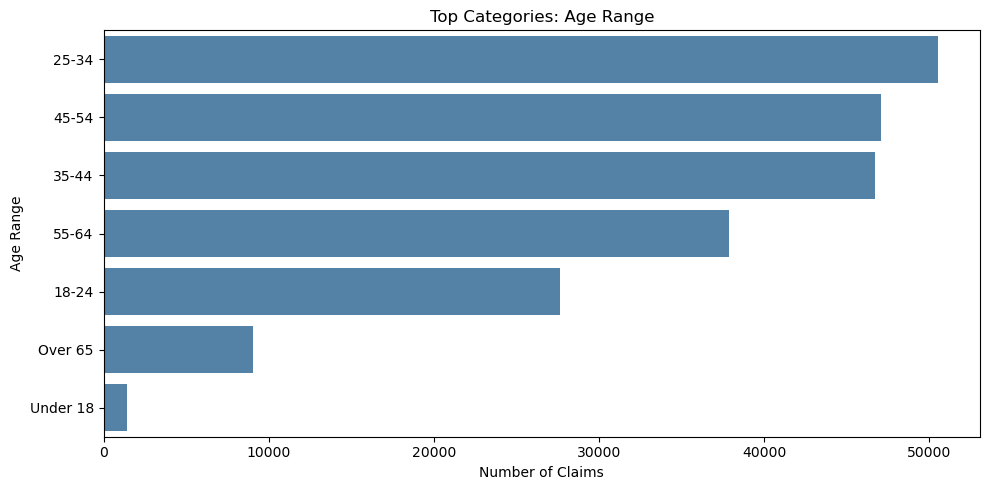

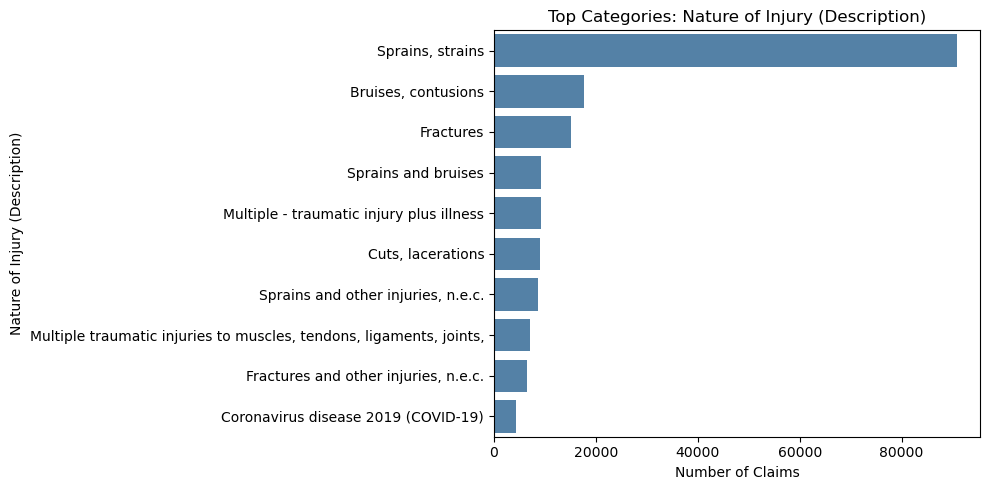

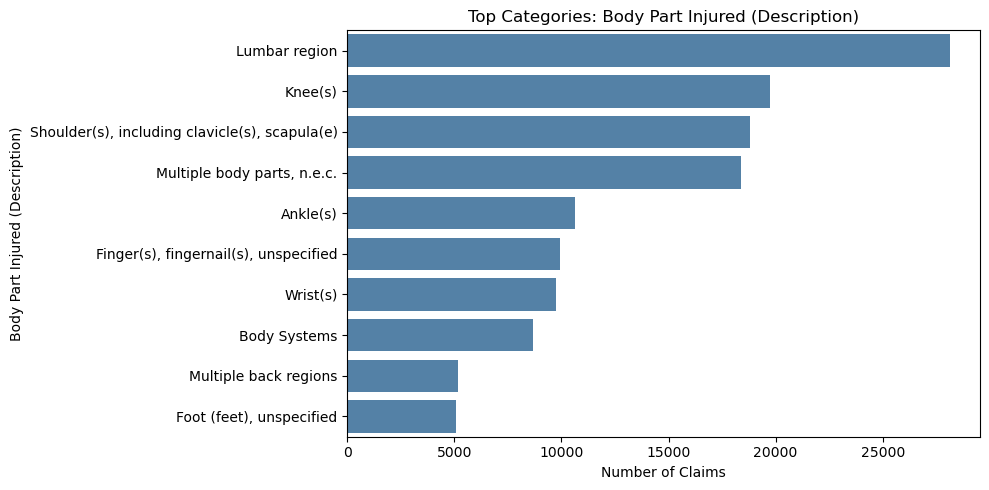

In [18]:
 import matplotlib.pyplot as plt
import seaborn as sns

# Select variables for visualization
plot_columns = [
    'Age Range',
    'Nature of Injury (Description)',
    'Body Part Injured (Description)'
]

# Create a separate chart for each variable
for col in plot_columns:

    # Select the 10 most common categories
    counts = df[col].value_counts().head(10)

    plt.figure(figsize=(10, 5))

    # Create horizontal bar chart
    sns.barplot(
        x=counts.values,
        y=counts.index,
        color='steelblue'
    )

    # Add descriptive titles and axis labels
    plt.title(f'Top Categories: {col}')
    plt.xlabel('Number of Claims')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

## EDA Visualization Findings

Age Range	Workers aged 25–34 account for the largest proportion of claims (22.94%).

Nature of Injury	Sprains and strains dominate, accounting for 41.23% of claims.

Body Part Injured	The lumbar region is the most frequently injured body part (12.77%).



## Analyze Yearly Claim Trends

Examining how the number of claims changes between 2015 and 2024. This helps identify historical trends and unusual fluctuations.

Claim Reference Year
2015    19550
2016    20447
2017    20978
2018    20996
2019    22399
2020    21859
2021    24384
2022    24947
2023    22993
2024    21749
Name: count, dtype: int64

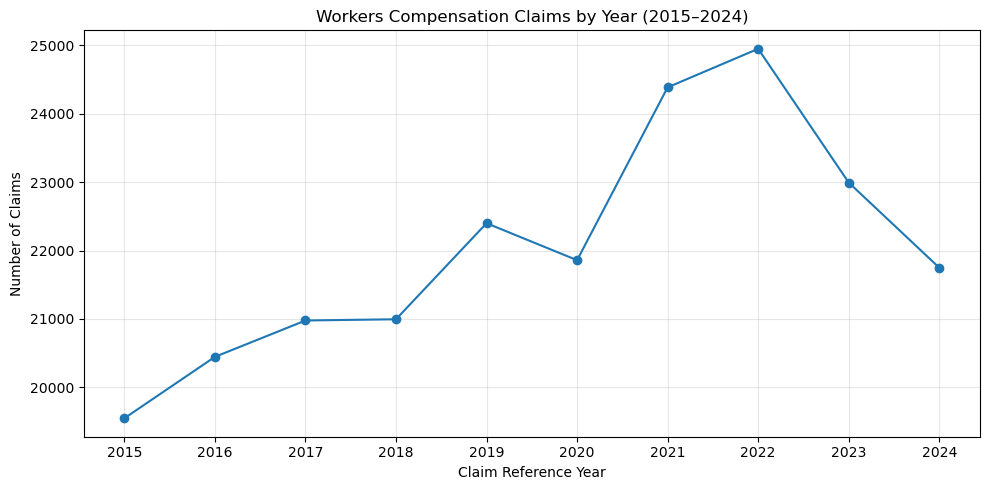

In [22]:
# Count claims for each reference year
yearly_claims = (
    df['Claim Reference Year']
    .value_counts()
    .sort_index()
)

# Display yearly claim counts
display(yearly_claims)

# Visualize yearly claim trends
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_claims.index,
    yearly_claims.values,
    marker='o'
)

# Add chart title and labels
plt.title('Workers Compensation Claims by Year (2015–2024)')
plt.xlabel('Claim Reference Year')
plt.ylabel('Number of Claims')
plt.xticks(yearly_claims.index)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- 2015–2019: Claims generally increased, from approximately 19,500 to 22,400.
- 2020: A slight decline occurred.
- 2021–2022: Claims increased significantly, reaching their highest level in 2022 at approximately 24,900.
- 2023–2024: Claims declined, reaching approximately 21,700 in 2024.
These fluctuations may reflect changes in workplace conditions, reporting patterns or other factors but we cannot determine their causes from this chart alone.

## Examine Missing Values and Special Codes

In [26]:
# Calculate missing values for every column
missing = df.isna().sum()

# Calculate percentage of missing values
missing_pct = (missing / len(df) * 100).round(2)

# Create a summary table
missing_table = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

# Display columns with missing values
display(
    missing_table[missing_table['Missing Count'] > 0]
    .sort_values('Missing %', ascending=False)
)

,Missing Count,Missing %
Employer Address 1,154046,69.92
Employer State,3690,1.67
NAICS Code (Description),1036,0.47
Employer City,1010,0.46
Occupation Description,106,0.05
Gender,30,0.01
Nature of Injury (Description),32,0.01
Employer Address 2,12,0.01
Employer Zip Code,9,0.00


frequency of placeholder values in the injury classification codes.

In [29]:
# Identify injury classification code columns
code_cols = [
    'Nature of Injury Code',
    'Body Part Injured Code',
    'Event of Injury Code',
    'Source of Injury Code',
    'Secondary Source of Injury Code'
]

# Count placeholder code 9999 in each column
for col in code_cols:
    count = (df[col] == 9999).sum()
    percentage = count / len(df) * 100

    print(f"{col}: {count:,} ({percentage:.2f}%)")

Nature of Injury Code: 171 (0.08%)
Body Part Injured Code: 179 (0.08%)
Event of Injury Code: 5,372 (2.44%)
Source of Injury Code: 9,336 (4.24%)
Secondary Source of Injury Code: 173,083 (78.57%)


## Investigate Placeholder Codes

Checking the descriptions associated with 9999 to understand whether it represents missing information an unknown category or a valid classification.

In [35]:
# Match each injury code with its description
code_pairs = {
    'Nature of Injury Code': 'Nature of Injury (Description)',
    'Body Part Injured Code': 'Body Part Injured (Description)',
    'Event of Injury Code': 'Event of Injury (Description)',
    'Source of Injury Code': 'Source of Injury (Description)',
    'Secondary Source of Injury Code':
        'Secondary Source of Injury (Description)'
}

# Examine descriptions associated with code 9999
for code_col, desc_col in code_pairs.items():

    print(f"\n{code_col}")

    # Show descriptions and their frequencies
    results = df.loc[
        df[code_col] == 9999, desc_col
    ].value_counts(dropna=False)

    display(results.head(10))


Nature of Injury Code


Nature of Injury (Description)
Nonclassifiable    171
Name: count, dtype: int64


Body Part Injured Code


Body Part Injured (Description)
Nonclassifiable    179
Name: count, dtype: int64


Event of Injury Code


Event of Injury (Description)
Nonclassifiable    5372
Name: count, dtype: int64


Source of Injury Code


Source of Injury (Description)
Nonclassifiable    9336
Name: count, dtype: int64


Secondary Source of Injury Code


Secondary Source of Injury (Description)
Nonclassifiable    173083
Name: count, dtype: int64

Placeholder Codes

Results confirm that code 9999 corresponds to "Nonclassifiable" across all five injury classification variables.

The most significant finding is that 78.57% of records have a nonclassifiable secondary injury source.

We should retain these values during EDA rather than automatically deleting records. However, we may consider excluding the secondary source variable during modeling because it contains limited classification information.

## Examine Injury Patterns Across Years

Examining how common injury types change between 2015 and 2024. This helps us understand whether injury patterns remain consistent over time.

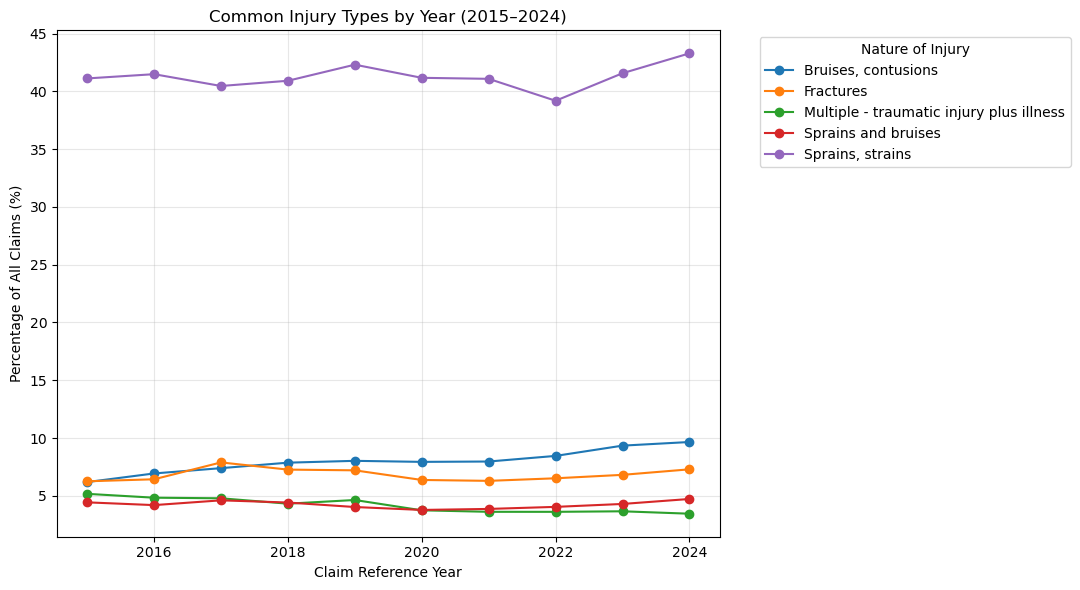

In [40]:
# Select the five most common injury types
top_injuries = (
    df['Nature of Injury (Description)']
    .value_counts()
    .head(5)
    .index
)

# Filter records to these injury types
injury_data = df[
    df['Nature of Injury (Description)'].isin(top_injuries)
]

# Count claims by year and injury type
injury_trends = pd.crosstab(
    injury_data['Claim Reference Year'],
    injury_data['Nature of Injury (Description)']
)

# Calculate each injury type's share of all claims per year
injury_pct = injury_trends.div(
    df.groupby('Claim Reference Year').size(),
    axis=0
) * 100

# Plot yearly injury patterns
ax = injury_pct.plot(figsize=(11, 6), marker='o')

plt.title('Common Injury Types by Year (2015–2024)')
plt.xlabel('Claim Reference Year')
plt.ylabel('Percentage of All Claims (%)')
plt.legend(title='Nature of Injury', bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Target Variable and Feature Engineering

